# 01 · Comprensión y auditoría de las imágenes H&M

**Pregunta:** ¿qué fotografías corresponden al problema que queremos resolver y cuáles podemos usar con garantías técnicas?

Queremos distinguir 26 tipos de prenda. Primero definimos ese alcance; después aplicamos controles iguales a todas las fotos. **El número final sale de esas reglas, no de una cifra deseada.** Las clases pueden tener tamaños diferentes.

Este notebook explica el origen, las etiquetas, la calidad y la preparación de las fotos. El 02 construye el conjunto local y sus particiones; el 03 analiza train y establece baselines; el 04 estudia una Dense. Las arquitecturas posteriores siguen el mismo conjunto y protocolo.

## Qué pide el profesor y cómo lo conectamos con este proyecto

La prioridad es entender los fundamentos con ejemplos sencillos y comparaciones explicables. El correo del profesor exige tres bloques: arquitecturas básicas (CNN, LSTM, GRU, RNN con atención, self-attention y Transformer), estrategias de aprendizaje con preentrenamiento autosupervisado y generación autorregresiva básica. El resumen inicial del informe tendrá como máximo tres páginas.

La clasificación visual es el hilo conductor de datos, Dense, CNN y recurrencia. La transferencia y zero-shot se conectan en 07 y 11; un generador de secuencias pequeño se desarrolla en 12. No hace falta un modelo enorme ni que cada arquitectura mejore a la anterior.

Un embedding es una representación, no generación por sí solo. Preentrenado no significa necesariamente autosupervisado. BERT original utiliza predicción de tokens enmascarados; el generador autorregresivo básico predice sucesivamente el siguiente token. Nuestra interpretación de los apuntes se distingue de los requisitos explícitos del correo. Las fuentes docentes están documentadas en `docs/requisitos-profesor.md`.

## Protocolo común del proyecto

Primero definimos las prendas que queremos clasificar. Después aplicamos los mismos controles de calidad a todas las fotos y conservamos **todas las que los superan**, aunque unas clases tengan más ejemplos. No se fija un número total ni se igualan las clases con cupos.

Las particiones se construyen sobre todos los grupos de producto elegibles. Los productos ya utilizados durante el desarrollo conservan su exposición: un producto de train no se convierte en un supuesto test nuevo. Los grupos nuevos completan aproximadamente 70/15/15 por clase. Se publican los recuentos reales.

**Antes de recortar train por coste, hay que medirlo.** El baseline usa todos los productos elegibles; 04 registra una época piloto y la estimación de tiempo/memoria. Si fuese necesario reducir datos en otro experimento, se justificaría con esa medición, solo en train y conservando validation/test. Una fotografía fuera de una muestra de cálculo no sería una fotografía de mala calidad.

La referencia es `config/experimental_protocol_v1.json`: macro-F1 primaria, accuracy y resultados por clase; pérdida inicial sin pesos, sin aumentos; normalización solo con train a la resolución de entrada. Tres semillas y coste computacional. Los pesos de clase se estudian como ablación: con frecuencias desiguales ya no suponemos que sean casi uno. El test predictivo se reserva hasta congelar las decisiones. Las métricas describen las 26 clases elegidas tras los controles, no todo el catálogo.

## 1. Decisiones explícitas y comprobables

`config/local_images_v1.json` fija los tipos de prenda, el lado mínimo, la preparación y las proporciones de grupos. **No contiene un cupo de fotos por clase.** También registra qué productos se han utilizado previamente en el desarrollo, para conservar la separación frente al test.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data/data_contract.py').is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src/data'))
from notebook_utils import setup, styled, es, numeric_axis, show_figure
setup()
config = json.loads((ROOT / 'config/local_images_v1.json').read_text(encoding='utf-8'))
SEED = config['seed']
display(Markdown(f"**Proyecto:** `{ROOT.name}` · **Python:** {platform.python_version()} · **Semilla:** {SEED}"))

**Proyecto:** `fashion-vision-dl` · **Python:** 3.12.2 · **Semilla:** 42

## 2. Auditoría completa y reanudable

`audit_images.py` verifica estructura y decodificación completa, orientación EXIF, dimensiones y modo de color. Calcula SHA-256 del fichero y de los píxeles RGB orientados: el primero identifica bytes y el segundo detecta imágenes idénticas aunque difieran sus metadatos. No detecta todos los duplicados aproximados.

La primera ejecución es costosa. Se guardan checkpoints cada mil archivos; una auditoría terminada se publica en `data/audit/runs/` y `data/audit/CURRENT.json`. Al reutilizarla se verifican checksums, metadatos, código e inventario del RAW si está conectado. Con el RAW desconectado se conserva el informe de la auditoría anterior; eso no verifica un origen externo que haya cambiado.

In [2]:
from audit_images import ensure_audit, read_audit
ensure_audit(workers=6)
audit_run, audit, summary = read_audit()
assert audit.article_id.is_unique
assert audit.article_id.str.fullmatch(r'\d+').all()
valid = audit.loc[audit.image_valid].copy()
inventory = pd.DataFrame({
    'Comprobación': ['Artículos en metadatos', 'Imágenes encontradas', 'Imágenes válidas',
                    'Imágenes corruptas/no admitidas', 'Artículos sin imagen', 'Imágenes sin metadatos',
                    'Filas repetidas por píxeles', 'Tamaño RAW (GB decimales)'],
    'Resultado': [summary['articles'], summary['images_found'], summary['images_valid'],
                  summary['images_invalid'], summary['missing_images'], summary['orphan_images'],
                  summary['duplicate_pixel_rows'], summary['raw_bytes']/1e9]
})
display(styled(inventory, 2))
display(Markdown(f"**Auditoría utilizada:** `{audit_run.relative_to(ROOT).as_posix()}`"))

Auditoría vigente verificada: C:\Iratxe\UPM\prdl y mllb\fashion-vision-dl\data\audit\runs\20261123T142408-a23fc6de


Comprobación,Resultado
Artículos en metadatos,"105.542,00"
Imágenes encontradas,"105.100,00"
Imágenes válidas,"105.100,00"
Imágenes corruptas/no admitidas,"0,00"
Artículos sin imagen,"442,00"
Imágenes sin metadatos,"0,00"
Filas repetidas por píxeles,"206,00"
Tamaño RAW (GB decimales),"30,56"


**Auditoría utilizada:** `data/audit/runs/20261123T142408-a23fc6de`

## 3. Enlace con los metadatos y calidad del origen

Cada nombre de archivo se enlaza con `article_id`. Una imagen ausente o inválida conserva su fila y un motivo de exclusión; nunca recibe una partición de modelado. No se interpreta una ausencia de foto como una característica de la prenda. El informe de imágenes huérfanas queda en la publicación de auditoría.

In [3]:
missing_by_class = audit.assign(sin_imagen=~audit.image_exists).groupby('product_type_name').agg(
    articulos=('article_id', 'size'), sin_imagen=('sin_imagen', 'sum')).sort_values('sin_imagen', ascending=False)
display(styled(missing_by_class.head(15)))
display(styled(audit[['width', 'height', 'file_bytes']].loc[audit.image_valid].describe(percentiles=[.05, .5, .95]).T, 1))
display(styled(valid.original_mode.value_counts().rename_axis('Modo original').to_frame('Imágenes')))
incidents = audit.loc[~audit.image_valid, ['article_id', 'product_type_name', 'reason']]
display(incidents.head(12))

Tipo de prenda,Artículos,Sin imagen
Sneakers,1.621,48
Sunglasses,621,46
Ballerinas,372,26
Sandals,757,24
T-shirt,7.904,24
Underwear bottom,2.748,23
Trousers,11.169,19
Necklace,581,18
Hair/alice band,854,18
Other accessories,1.034,17


Referencia,Número,Media,Desv. típica,Mínimo,5%,50%,95%,Máximo
width,"105.100,0","1.191,3","186,0","222,0","1.166,0","1.166,0","1.396,0","3.494,0"
height,"105.100,0","1.750,0","0,1","1.749,0","1.750,0","1.750,0","1.750,0","1.750,0"
file_bytes,"105.100,0","290.742,5","162.885,2","33.431,0","111.950,9","251.798,0","598.768,6","1.849.119,0"


Modo original,Imágenes
RGB,105.099
L,1


,article_id,product_type_name,reason
88,0174057028,Pyjama jumpsuit/playsuit,missing_image
117,0179208001,Leggings/Tights,missing_image
258,0212042043,Sneakers,missing_image
259,0212042066,Sneakers,missing_image
261,0212629004,Dress,missing_image
294,0215324023,Sunglasses,missing_image
305,0216961011,Hair/alice band,missing_image
316,0218354021,Vest top,missing_image
445,0241602023,Blazer,missing_image
607,0268305006,Sunglasses,missing_image


## 4. Comparación de las taxonomías y elección del objetivo

`garment_group_name` combina material (`Jersey`, `Knitwear`), uso y secciones comerciales; `product_group_name` agrupa por zona corporal y resulta demasiado grueso para el objetivo propuesto. `product_type_name` ofrece nombres de objetos más directamente relacionados con la forma visual, aunque sigue teniendo clases próximas y posibles errores.

La siguiente medida de **pureza respecto al tipo** suma el tamaño del tipo mayoritario dentro de cada grupo y divide por el número de imágenes válidas. Describe cómo se mezclan los tipos en cada taxonomía; no mide precisión de un clasificador.

In [4]:
rows = []
for target in ['garment_group_name', 'product_group_name', 'product_type_name', 'index_group_name']:
    counts = valid[target].value_counts()
    cross = pd.crosstab(valid[target], valid.product_type_name)
    rows.append({'Objetivo': target, 'Clases': len(counts), 'Clase mayor (%)': 100*counts.iloc[0]/len(valid),
                 'Unknown (%)': 100*valid[target].eq('Unknown').mean(),
                 'Pureza respecto al tipo (%)': 100*cross.max(axis=1).sum()/len(valid)})
display(styled(pd.DataFrame(rows).set_index('Objetivo'), 2))
mixtures = pd.crosstab(valid.garment_group_name, valid.product_type_name)
example = pd.DataFrame({'Tipos distintos': mixtures.gt(0).sum(axis=1),
                        'Tipo mayoritario': mixtures.idxmax(axis=1),
                        'Pureza (%)': 100*mixtures.max(axis=1)/mixtures.sum(axis=1)})
display(styled(example.sort_values('Pureza (%)').head(10), 1))

Objetivo,Clases,Clase mayor (%),Unknown (%),Pureza respecto al tipo (%)
Grupo de prendas,21,"20,38","3,68","43,81"
product_group_name,19,"40,61","0,12","39,00"
Tipo de prenda,131,"10,61","0,12","100,00"
Segmento comercial,5,"37,63","0,00","13,58"


Grupo de prendas,Tipos distintos,Tipo mayoritario,Pureza (%)
Accessories,81,Bag,"11,0"
Unknown,68,Trousers,"15,3"
Woven/Jersey/Knitted mix Baby,39,Trousers,"22,0"
Jersey Fancy,42,T-shirt,"23,8"
Jersey Basic,17,T-shirt,"25,5"
Special Offers,49,Dress,"26,1"
Shoes,21,Sneakers,"31,3"
"Under-, Nightwear",35,Underwear bottom,"36,3"
Swimwear,14,Swimwear bottom,"42,9"
Dresses/Skirts girls,10,Dress,"46,2"


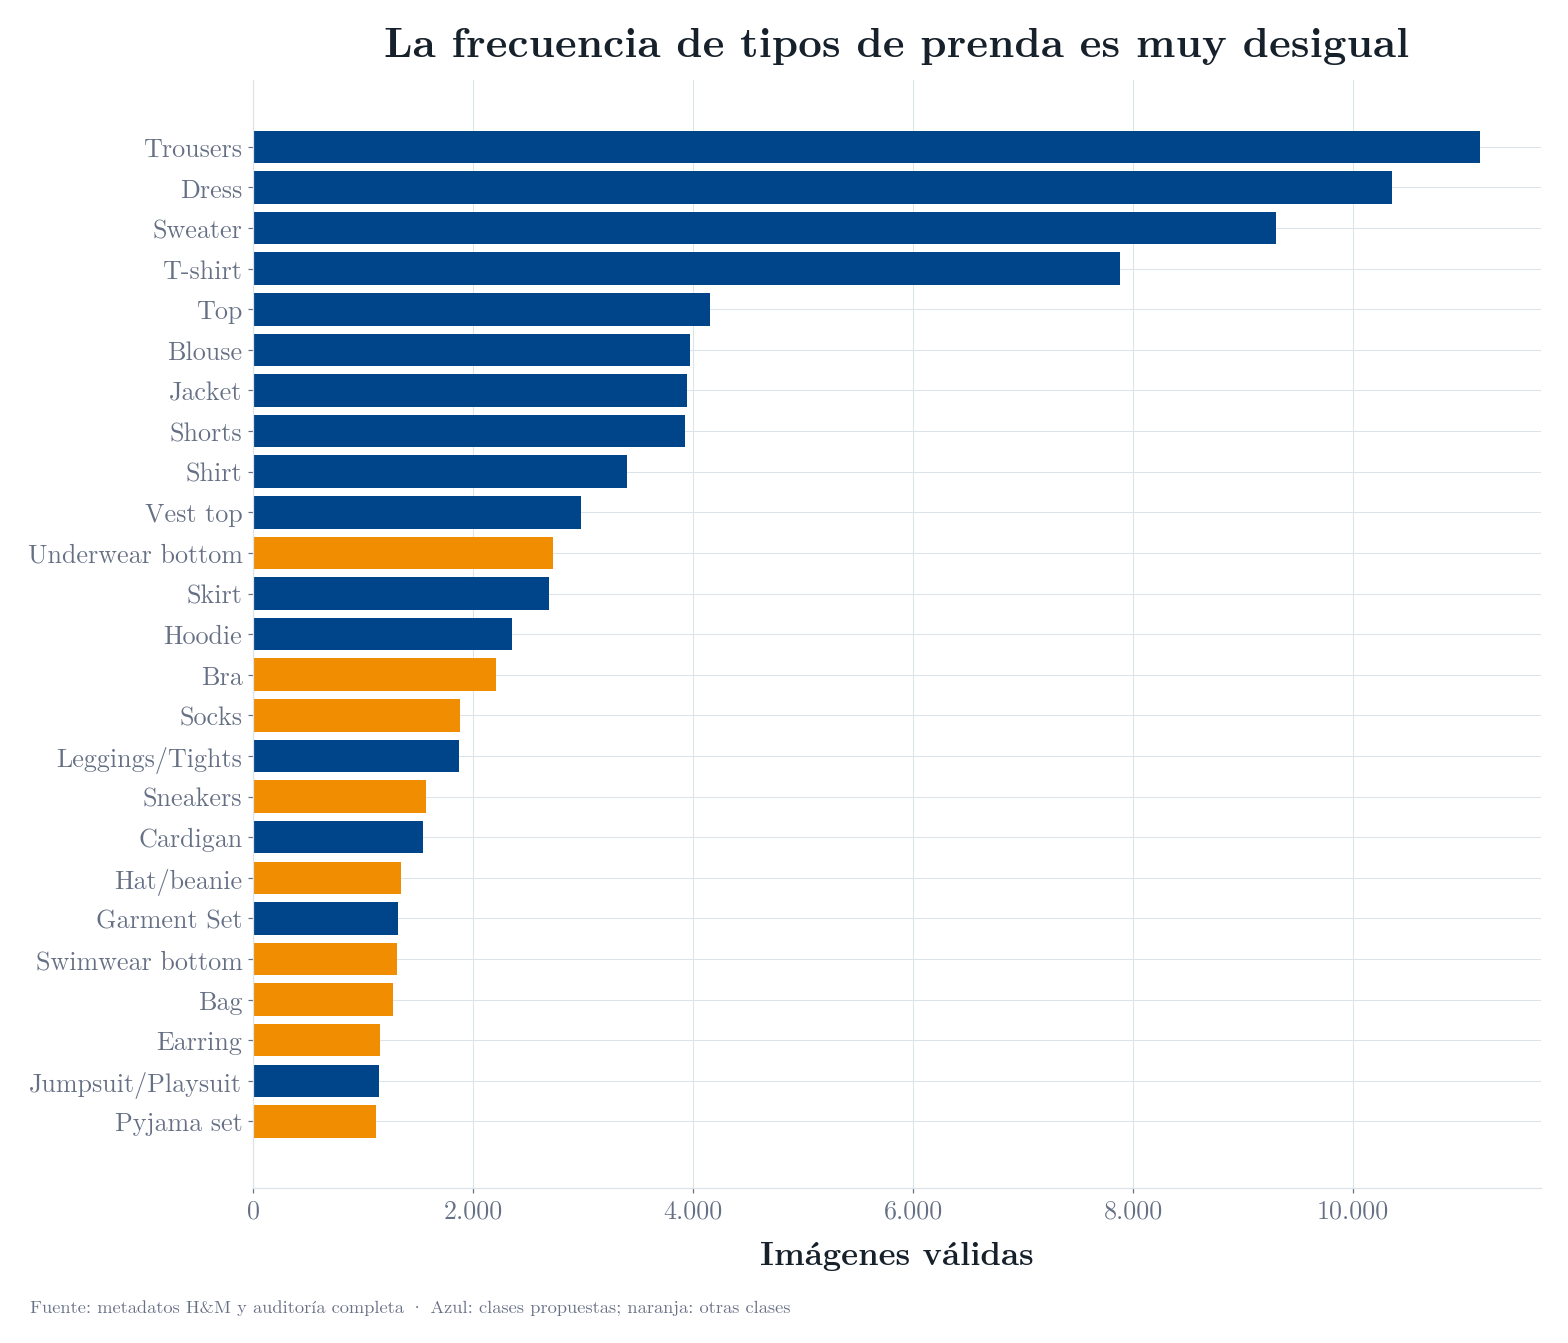

In [5]:
counts = valid.product_type_name.value_counts().head(25).sort_values()
proposed = counts.index.isin(config['include_classes'])

def draw(T):
    fig, ax = plt.subplots(figsize=T.pick((11, 8), (14, 12)))
    ax.barh(counts.index, counts.values, color=[T.primary if keep else T.reference for keep in proposed])
    ax.set(title='Garment type frequency is highly uneven', xlabel='Valid images')
    ax.xaxis.grid(True); ax.set_axisbelow(True); numeric_axis(ax)
    return fig

show_figure(draw, ROOT, '01_product_types',
            lambda T: f"Source: H&M metadata and full audit · Blue: proposed classes; {T.pick('grey', 'orange')}: other classes")

## 5. Cómo son las fotos y por qué preparamos copias más pequeñas

Primero miramos las fotografías originales. Después decidimos cómo crear una copia de trabajo que ocupe menos. **Los originales se conservan.**

### 5.1. ¿Vertical, cuadrada u horizontal?

Escribimos las dimensiones en este orden: **ancho × alto**. Para conocer la forma dividimos el ancho entre el alto.

| Forma | Cómo reconocerla | Ancho ÷ alto | Ejemplo de ancho × alto |
|---|---|---|---|
| **Vertical** | Es más alta que ancha | Menor que 1 | 400 × 800 → 0,5 |
| **Cuadrada** | Tiene el mismo ancho y alto | Igual a 1 | 400 × 400 → 1 |
| **Horizontal** | Es más ancha que alta | Mayor que 1 | 800 × 400 → 2 |

El **gráfico azul** cuenta cuántas fotos tienen cada proporción. Cada barra agrupa proporciones cercanas. El pico alrededor de 0,67 indica que predominan las fotos verticales: su ancho es aproximadamente dos tercios de su alto. La línea gris discontinua marca el valor 1, que corresponde a una foto cuadrada.

### 5.2. ¿De qué fotos son los kB?

El **gráfico verde azulado incluye las 105.100 imágenes originales válidas de la auditoría**, de todas las clases, antes de aplicar el alcance y los controles del proyecto. Se mide cada JPEG por separado. No incluye los 442 artículos sin foto.

- **Eje horizontal:** cuánto ocupa cada archivo JPEG original. Aquí, 1 kB son 1.000 bytes.
- **Eje vertical:** cuántas fotos están dentro de cada intervalo de peso. Una barra alta significa muchas fotos con un peso parecido.

Los kB indican espacio en disco. **No son el ancho ni el alto de la imagen.** Dos fotos con los mismos píxeles pueden ocupar distinto espacio por su contenido y compresión. Este gráfico describe los archivos originales; no demuestra por sí solo qué resolución debemos elegir.

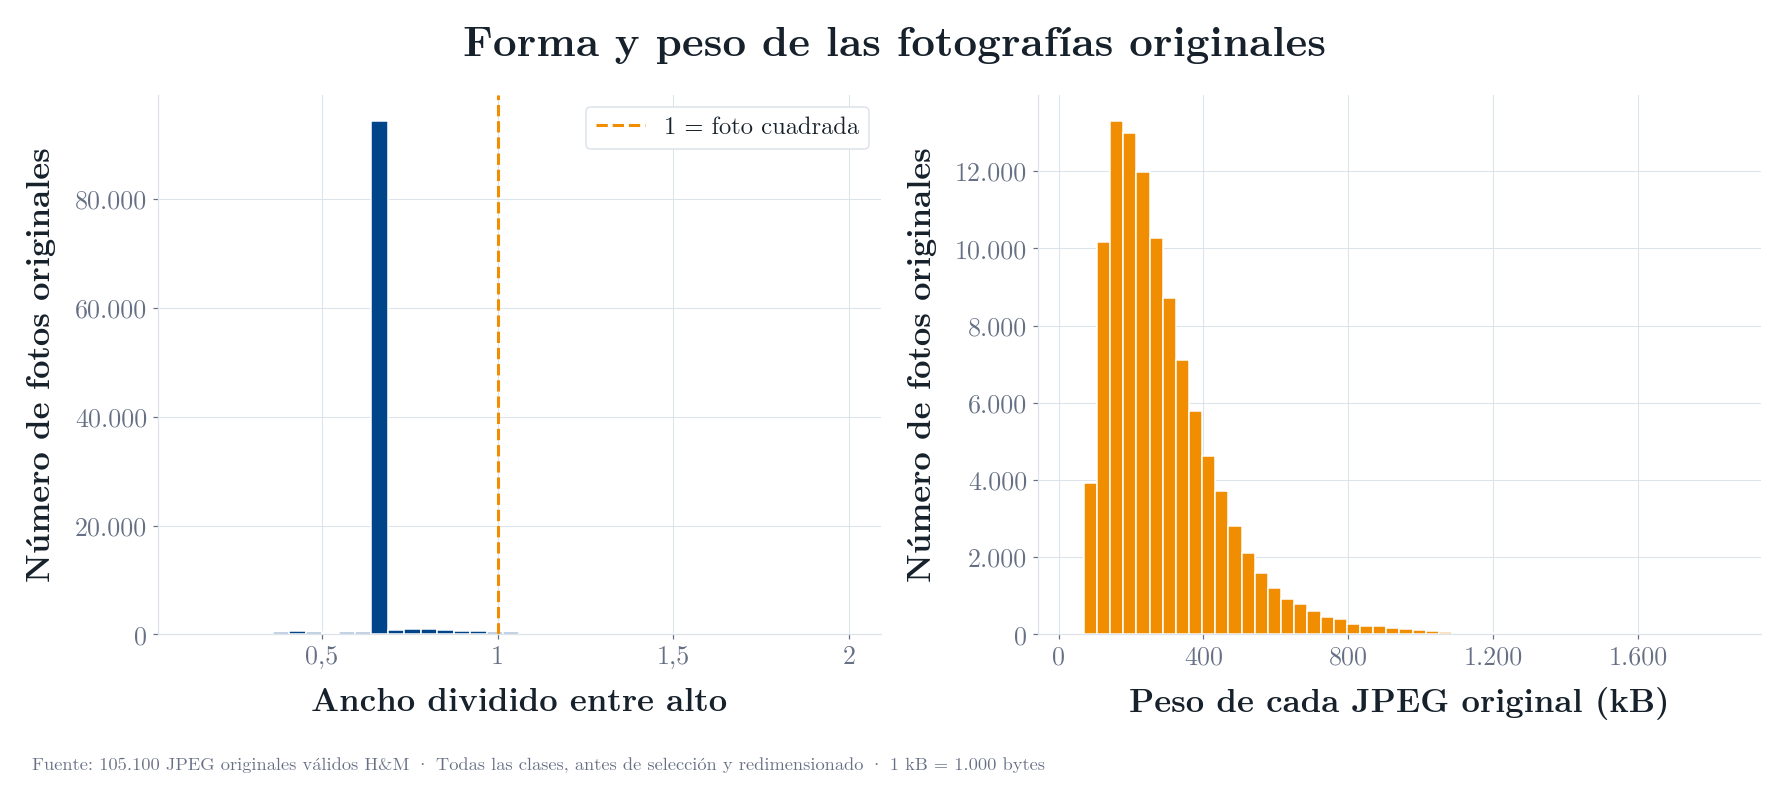

In [6]:
from matplotlib.ticker import MaxNLocator, FuncFormatter
from src.visualization.style import format_number

def draw(T):
    fig, axes = plt.subplots(1, 2, figsize=T.pick((13, 5.5), (16, 7)))
    axes[0].hist(valid.width / valid.height, bins=40, color=T.primary, edgecolor='white')
    axes[0].axvline(1, color=T.reference, linestyle='--', label='1 = square photo')
    axes[0].legend(loc='upper right')
    axes[0].set(xlabel='Width divided by height', ylabel='Number of original photos')
    axes[1].hist(valid.file_bytes / 1000, bins=50, color=T.secondary, edgecolor='white')
    axes[1].set(xlabel='Size of each original JPEG (kB)', ylabel='Number of original photos')
    for ax in axes:
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
        numeric_axis(ax, 'y')
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: format_number(value)))
    fig.suptitle('Shape and file size of the original photographs')
    return fig

show_figure(draw, ROOT, '01_image_properties',
            f'Source: {es(len(valid))} valid original H&M JPEGs · All classes, before selection and resizing · 1 kB = 1.000 bytes')

### 5.3. ¿Por qué elegimos 224 × 224?

Por dos motivos prácticos:
- **Tener un tamaño común, pero conservando proporción**: facilita pasar varias fotografías juntas a la red.
- **Reducir el trabajo y el espacio**: procesar fotos pequeñas suele requerir menos memoria y cálculo que procesar los originales grandes.
Pero hay una distinción importante: necesitar un tamaño común no demuestra que ese tamaño tenga que ser exactamente 224.

¿Cómo convertimos una foto vertical en cuadrada sin deformarla?

Imagina una fotografía de 400 × 800:

| Paso | Qué hacemos | Resultado |
|---|---|---|
| **Uno** | Reducimos ancho y alto en la misma proporción | 112 × 224 |
| **Dos** | Añadimos 56 píxeles blancos a cada lado | 224 × 224 |

La prenda mantiene su forma. El cuadrado lo conseguimos añadiendo espacio alrededor, en lugar de ensanchar la ropa. Elegimos blanco como fondo añadido fijo. Es una decisión sencilla y uniforme; no hemos comprobado que sea mejor que cualquier otro color.


¿Por qué 224 y no 200 o 256? Elegimos un tamaño habitual como punto de partida práctico, no porque hayamos comprobado que da más aciertos. Por ejemplo, [los pesos de ResNet-18 documentados por Torchvision](https://docs.pytorch.org/vision/0.22/models/generated/torchvision.models.resnet18.html) usan una entrada final de 224 × 224. Eso **no significa que nuestra preparación sea idéntica**: al usar un modelo ya entrenado, revisaremos también sus instrucciones de preparación.

### 5.4. ¿Cuánto espacio ahorramos realmente?

Si 02 ya está ejecutado, la siguiente tabla compara **las mismas fotos seleccionadas** en sus dos versiones. Así no confundimos el ahorro por reducir las fotos con el ahorro por elegir menos fotos. En una primera ejecución de 01, esta comprobación puede quedar pendiente hasta completar 02.

También guardamos las copias como JPEG con calidad 90. Es un ajuste de compresión, **no significa conservar el 90 % del detalle**. El cambio de tamaño y esta compresión contribuyen juntos al ahorro.

In [7]:
# Esta comprobación solo lee metadatos; no abre imágenes ni cambia los datos.
pointer = ROOT / 'data/processed/CURRENT.json'
if pointer.exists():
    prepared_run = pointer.parent / json.loads(pointer.read_text())['run_dir']
    from data_contract import sha256
    checks = json.loads((prepared_run / 'checksums.json').read_text())
    assert sha256(prepared_run / 'image_manifest.csv.gz') == checks['image_manifest.csv.gz']
    prepared = pd.read_csv(prepared_run / 'image_manifest.csv.gz',
                           usecols=['article_id', 'split', 'file_bytes', 'prepared_bytes', 'width', 'height'],
                           dtype={'article_id': 'string'})
    chosen = prepared.loc[prepared.split.isin(['train', 'validation', 'test'])]
    comparison = pd.DataFrame({
        'Versión de las mismas fotos': ['Originales seleccionados', 'Copias preparadas'],
        'Fotografías': [len(chosen), len(chosen)],
        'Espacio en disco (MB)': [chosen.file_bytes.sum() / 1_000_000,
                                  chosen.prepared_bytes.sum() / 1_000_000],
    })
    display(styled(comparison, 2))
    enlarged = int(chosen[['width', 'height']].max(axis=1).lt(config['image_size']).sum())
    display(Markdown(f"**Comprobación:** {es(enlarged)} de las {es(len(chosen))} fotos seleccionadas necesitarían agrandarse para llegar a {config['image_size']} píxeles en su lado largo. La tabla mide espacio en disco, no aciertos del clasificador."))
else:
    display(Markdown('**Pendiente:** ejecutar 02 para medir el espacio de las copias preparadas frente a sus originales.'))

**Pendiente:** ejecutar 02 para medir el espacio de las copias preparadas frente a sus originales.

### 5.5. Qué perdemos y qué queda por comprobar

Al reducir una foto se pueden perder detalles, como textura, botones o bordes finos. La compresión JPEG también puede quitar información. Por eso el ahorro de espacio **no demuestra que la clasificación conserve la misma calidad**.

**Guardar a 224 × 224 tampoco obliga a entrenar todas las redes a ese tamaño.** La Dense de 04 recibe copias reducidas a 64 × 64 para limitar su coste. Compararemos otras resoluciones manteniendo los mismos productos y los mismos grupos de entrenamiento, validación y prueba antes de afirmar qué tamaño conviene más.

Las copias de 224 no permiten recuperar los detalles que se han perdido. Si queremos probar tamaños mayores, habrá que volver a los originales. El relleno blanco también puede influir en lo que aprende la red; debe documentarse y mantenerse fijo en las comparaciones que pretendan cambiar solo el tipo de red.

## 6. Qué prendas entran y qué controles aplicamos

### 6.1. Una regla de alcance, no una lista elegida a mano

Incluimos todos los tipos que H&M coloca en estas tres familias de `product_group_name`:

- **Garment Upper body** — parte superior: Blazer, Blouse, Bodysuit, Cardigan, Coat, Hoodie, Jacket, Outdoor Waistcoat, Polo shirt, Shirt, Sweater, T-shirt, Tailored Waistcoat, Top y Vest top.
- **Garment Lower body** — parte inferior: Leggings/Tights, Outdoor trousers, Shorts, Skirt y Trousers.
- **Garment Full body** — cuerpo completo: Costumes, Dress, Dungarees, Garment Set, Jumpsuit/Playsuit y Outdoor overall.

En este catálogo son **26 etiquetas**. Queremos predecir el tipo concreto (`product_type_name`), no únicamente una de las tres familias. La configuración guarda las familias y la lista completa de sus tipos; el preparador comprueba que coincidan para no omitir etiquetas silenciosamente.

**Top también entra**, con las mismas reglas que cualquier otro tipo. También entran conjuntos y disfraces porque pertenecen a la familia corporal elegida. No cambiamos la clasificación comercial de H&M según nuestra impresión de una fotografía: por ejemplo, Bodysuit pertenece a Upper body en estos metadatos.

Calzado, accesorios, interior, baño y ropa de dormir quedan fuera de este alcance. Es una decisión explícita de qué problema estudiamos, no una afirmación de que esas imágenes sean malas. Las etiquetas pueden solaparse visualmente; lo analizaremos en los errores, sin quitar las clases más difíciles de antemano.

### 6.2. Qué controles debe superar cada foto

1. Tener imagen enlazada con su artículo y poder decodificarla completamente.
2. Pertenecer a las familias elegidas y tener al menos 64 píxeles en su lado menor.
3. No pertenecer a un grupo de producto con etiquetas contradictorias.
4. No ser una copia exacta de otra imagen: conservamos un representante y la conexión del grupo.
5. Tras preparar las copias, repetir los controles de igualdad de píxeles y conflictos.

**Conservamos todas las fotos que superan estas reglas.** Las clases no tienen por qué sumar lo mismo. La falta de grupos independientes suficientes para repartir una clase se informa como un problema que revisar; no se elimina silenciosamente su etiqueta.

### 6.3. Cuándo tendría sentido hacer una muestra

Después de construir el conjunto y separar sus grupos, medimos tiempo y memoria de entrenamiento. Solo un coste excesivo justificaría una muestra computacional de train, registrada como tal; validation y test conservarían sus productos. Esta decisión no convierte una foto válida en una foto de mala calidad.

In [8]:
from prepare_local import select_candidates
selection, candidates = select_candidates(audit, config)
display(styled(pd.Series(config, name='Configuración').to_frame()))
selection_table = pd.DataFrame({'Válidas en origen': valid.product_type_name.value_counts(),
                                'Conservadas antes de preparar': candidates.label.value_counts()}).fillna(0).astype(int)
display(styled(selection_table.loc[config['include_classes']]))
display(styled(selection.exclusion_reason.replace('', 'eligible').value_counts().rename_axis('Motivo').to_frame('Artículos')))
assert set(candidates.label) == set(config['include_classes'])
assert not selection.exclusion_reason.isin(['class_budget','visual_audit_group']).any()
display(Markdown(f"**Resultado de los controles previos:** {es(len(candidates))} fotos. Su número no se ha fijado por adelantado."))

Referencia,Configuración
preparation_version,1.0.0
target,Tipo de prenda
include_product_groups,"['Garment Upper body', 'Garment Lower body', 'Garment Full body']"
include_classes,"['Blazer', 'Blouse', 'Bodysuit', 'Cardigan', 'Coat', 'Hoodie', 'Jacket', 'Outdoor Waistcoat', 'Polo shirt', 'Shirt', 'Sweater', 'T-shirt', 'Tailored Waistcoat', 'Top', 'Vest top', 'Leggings/Tights', 'Outdoor trousers', 'Shorts', 'Skirt', 'Trousers', 'Costumes', 'Dress', 'Dungarees', 'Garment Set', 'Jumpsuit/Playsuit', 'Outdoor overall']"
min_side,64
min_class_images,3
image_size,224
jpeg_quality,90
padding_rgb,"[255, 255, 255]"
Semilla,42


Referencia,Válidas en origen,Conservadas antes de preparar
Blazer,1.108,1.096
Blouse,3.975,3.934
Bodysuit,911,906
Cardigan,1.546,1.539
Coat,460,460
Hoodie,2.356,2.283
Jacket,3.940,3.909
Outdoor Waistcoat,154,154
Polo shirt,448,427
Shirt,3.403,3.384


Motivo,Artículos
eligible,74.526
class_not_selected,29.374
conflicting_group_labels,1.048
missing_image,442
exact_pixel_duplicate,152


**Resultado de los controles previos:** 74.526 fotos. Su número no se ha fijado por adelantado.

## 7. Inspección visual desde train

La galería completa se puede mostrar cuando 02 haya fijado los grupos de las 26 etiquetas. Así sabemos qué fotos pertenecen a train antes de mirarlas para estudiar las clases. Si todavía no existe esa preparación, esta sección queda pendiente; en 03 se hará la revisión sistemática de train.

Se muestran hasta dos productos independientes por tipo. No es una estimación del ruido de toda la categoría ni una razón para excluir las etiquetas que parezcan difíciles. Los dos ejemplos de Top vistos durante el desarrollo están registrados en el lado de train para que no reaparezcan como un test supuestamente nuevo.

In [9]:
pointer = ROOT / 'data/processed/CURRENT.json'
scope_ready = False
if pointer.exists():
    prepared_root = ROOT / 'data/processed'
    prepared_run = prepared_root / json.loads(pointer.read_text())['run_dir']
    prepared_config = json.loads((prepared_run/'config.json').read_text())
    scope_ready = (set(prepared_config.get('include_classes', [])) == set(config['include_classes'])
                   and set(prepared_config.get('include_product_groups') or []) == set(config['include_product_groups']))
if not scope_ready:
    display(Markdown('**Galería pendiente:** ejecutar 02 con las tres familias y las 26 etiquetas. Después se puede volver a esta sección o continuar con la revisión de train en 03.'))
else:
    from prepare_local import verify_run
    visual_manifest = verify_run(prepared_run, verify_assets=False)
    visual = (visual_manifest.loc[visual_manifest.split.eq('train')]
              .sort_values('article_id').drop_duplicates('group_id')
              .groupby('label', sort=True).head(2).sort_values(['label','article_id']))
    assert visual.split.eq('train').all()
    page_size = 12
    for page in range((len(visual)+page_size-1)//page_size):
        part = visual.iloc[page*page_size:(page+1)*page_size]
        photos = []
        for row in part.itertuples():
            with Image.open(prepared_root/row.image_path) as image:
                photos.append(image.copy())  # Cada foto se lee una vez para los dos estilos.

        def draw(T, part=part, photos=photos, page=page):
            ncols = min(6, len(part))
            nrows = (len(part)+ncols-1)//ncols
            fig, axes = plt.subplots(nrows, ncols, figsize=(3.2*ncols, 4.5*nrows))
            axes = np.atleast_1d(axes)
            for ax, row, photo in zip(axes.flat, part.itertuples(), photos):
                ax.imshow(photo)
                ax.set_title(f'{row.label}\n{row.article_id}')
            for ax in axes.flat: ax.axis('off')
            fig.suptitle(f'Garment types from train · Block {page+1}')
            return fig

        show_figure(draw, ROOT, f'01_training_examples_{page+1}', 'Source: prepared H&M cohort · Up to two products per type · Train only')

**Galería pendiente:** ejecutar 02 con las tres familias y las 26 etiquetas. Después se puede volver a esta sección o continuar con la revisión de train en 03.

**Top no es una excepción.** Sus fotos pasan los mismos controles que las de polos, abrigos o camisetas. Una galería puede ayudar a estudiar la variedad de una etiqueta, pero dos imágenes no permiten declarar mala toda una categoría ni justificar su exclusión.

## 8. Qué pasa al notebook 02

- Los 26 tipos de prenda definidos, con todas sus fotos elegibles después de controles iguales.
- Copias RGB224 con proporción conservada, relleno blanco y JPEG calidad 90. La explicación del tamaño no decide cuántas fotos conservar.
- Particiones por grupos de producto y píxeles originales/preparados, aproximadamente 70/15/15 por clase. Se preserva la exposición de los productos ya usados y se publican las proporciones reales.
- Duplicados exactos reducidos a un representante; grupos de etiquetas contradictorias excluidos. Los casi duplicados y errores semánticos siguen siendo limitaciones.
- Normalización y pesos opcionales calculados con train. Tener más fotos de una clase no obliga a equilibrarla ni a usar pesos automáticamente.
- Coste medido antes de justificar cualquier reducción de train. El número de imágenes preparadas es una consecuencia de los filtros.

El RAW se conserva hasta disponer de una copia externa verificada. Solo hay una propuesta activa del proyecto: `CURRENT.json` identifica sus datos. Las ejecuciones históricas internas permiten auditar cambios, pero no son dos datasets experimentales presentados en paralelo.

In [10]:
display(Markdown(f"**Resultado real de la auditoría:** {es(summary['images_valid'])} imágenes válidas, "
                 f"{es(summary['missing_images'])} artículos sin imagen y {es(summary['images_invalid'])} imágenes inválidas. "
                 f"Antes de preparar quedan {es(len(candidates))} candidatos en {es(candidates.label.nunique())} clases. "
                 "La publicación definitiva y sus comprobaciones se generan en el notebook 02."))

**Resultado real de la auditoría:** 105.100 imágenes válidas, 442 artículos sin imagen y 0 imágenes inválidas. Antes de preparar quedan 74.526 candidatos en 26 clases. La publicación definitiva y sus comprobaciones se generan en el notebook 02.